# Experimental: cross-section in height from pressure-level data, without vertical interpolation

**This is an experimental example.** It is a variant of [cross_section_height_pl_orog.ipynb](cross_section_height_pl_orog.ipynb), which reproduces the Metview gallery example [Cross Section in Height for Pressure Level Data with Orography](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_height_pl_orog.html) with earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. That notebook interpolates the temperature from the pressure levels to regular height levels (0 to 3000 m every 20 m) with `earthkit.meteo.vertical.interpolate_pressure_to_height_levels`. **This variant does not use vertical interpolation.** The temperature is contoured directly on the heights of the pressure levels, which form an uneven, curvilinear grid: each level has a different height at each point of the line. The horizontal part (the line and the regridding onto it) uses the new `earthkit.geo.polyline` module, whose interface may still change. The heights of the levels are computed with `earthkit.meteo.vertical.geometric_height_from_geopotential`.

The notebook reads a GRIB file. It contains forecast data of 2020-08-22 00 UTC. 

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import sample_polyline
from earthkit.meteo import vertical

## Load the data

The file contains the temperature `t` and the geopotential `z` on the pressure levels 1000, 925, 850, 700, 400, 500 and 300 hPa (the order of the levels in the file is not monotonic: 400 comes before 500), for the forecast step of 12 h, and the surface geopotential `z` from the analysis (step 0). It is a GRIB1 file on a regular 0.5° latitude-longitude grid over the area 40–51°N, 93–84°W. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_pl_orog.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_pl_orog.grib:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

15 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
1,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,1000,pressure,0,regular_ll
2,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
3,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,925,pressure,0,regular_ll
4,t,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll
5,z,2020-08-22 12:00:00,2020-08-22,0 days 12:00:00,850,pressure,0,regular_ll


## Select the temperature, the geopotential and the surface geopotential

We select `t` and `z` on the pressure levels, which gives 7 fields each, and `z` at the surface, which gives a single field. The geopotential is in m²/s². The cell prints the pressure levels of the fields in the order they have in the file.

In [3]:
t = ds.sel({"parameter.variable": "t", "vertical.level_type": "pressure"})
z = ds.sel({"parameter.variable": "z", "vertical.level_type": "pressure"})
zs = ds.sel({"parameter.variable": "z", "vertical.level_type": "surface"})

print(len(t), "t fields, levels (hPa):", [f.get("vertical.level") for f in t])
print(len(z), "z fields, levels (hPa):", [f.get("vertical.level") for f in z])
print(len(zs), "surface z field")

7 t fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
7 z fields, levels (hPa): [1000, 925, 850, 700, 400, 500, 300]
1 surface z field


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (50.21°N, 91.82°W) to (40.82°N, 84.71°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [4]:
lats, lons = sample_polyline([50.21, 40.82], [-91.82, -84.71], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(50.21), np.float64(-91.82)) (np.float64(40.82), np.float64(-84.71))


## Regrid onto the line

The temperature, the geopotential and the surface geopotential are regridded onto the 200 points of the line, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each field of the input. MIR may print some `GridUnknownError` and `ECCODES` lines during this step (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message), they come from the C libraries and do not stop the regridding.

In [5]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}

t_line = ekg.regrid(t, out_grid=out_grid)
z_line = ekg.regrid(z, out_grid=out_grid)
zs_line = ekg.regrid(zs, out_grid=out_grid)
print(len(t_line), "t fields, shape of the values:", t_line[0].values.shape)
print(len(z_line), "z fields, shape of the values:", z_line[0].values.shape)
print(len(zs_line), "surface z field, shape of the values:", zs_line[0].values.shape)

7 t fields, shape of the values: (200,)
7 z fields, shape of the values: (200,)
1 surface z field, shape of the values: (200,)


ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. Output must be a higher edition!
ECCODES WARNING grib_util_set_spec_: 'unstructured_grid' specified but input is GRIB edition 1. O

## Sort the levels by pressure

The levels of the file are not monotonic in pressure (400 hPa is before 500 hPa). Here we contour the temperature directly on the heights of the levels, and unsorted levels would make neighbouring cells of the grid overlap, so they must be sorted. We sort the levels by decreasing pressure, from 1000 to 300 hPa, and sort the temperature and the geopotential each into this same decreasing-pressure order. The cell asserts that the pressure levels of `t` and `z` are the same and that they are monotonic. The arrays have the shape (level, point).

In [6]:
p_t = np.array([f.get("vertical.level") for f in t_line])
p_z = np.array([f.get("vertical.level") for f in z_line])
order = np.argsort(p_t)[::-1]  # decreasing pressure

levels = p_t[order]
T = np.stack([f.values for f in t_line])[order]  # K, (level, point)
Z = np.stack([f.values for f in z_line])[np.argsort(p_z)[::-1]]  # m2/s2, (level, point)
ZS = zs_line[0].values  # m2/s2, (point)

assert np.array_equal(np.sort(p_t), np.sort(p_z)), "t and z must be on the same levels"
assert np.all(np.diff(levels) < 0), "the pressure levels must be monotonic"
print("levels (hPa):", levels.tolist())
print(T.shape, Z.shape, ZS.shape)

levels (hPa): [1000, 925, 850, 700, 500, 400, 300]
(7, 200) (7, 200) (200,)


## Compute the heights

[geometric_height_from_geopotential()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` converts the geopotential to geometric height in m. It gives the height `H` of each pressure level at each point of the line, and the height `HS` of the surface, which is the orography. The cell prints the range of the height of the 1000 hPa level and of the orography. The 1000 hPa level is below the ground everywhere on this line, because the orography is higher than the height of this level.

In [7]:
H = vertical.geometric_height_from_geopotential(Z)  # m, (level, point)
HS = vertical.geometric_height_from_geopotential(ZS)  # m, (point)

print(f"height of the 1000 hPa level: {H[0].min():.0f} to {H[0].max():.0f} m")
print(f"orography: {HS.min():.0f} to {HS.max():.0f} m")
assert levels[0] == 1000 and np.all(H[0] < HS), "1000 hPa is expected to be below ground on the line"

height of the 1000 hPa level: 82 to 125 m
orography: 173 to 532 m


## Check that the lowest level is below the ground

Without vertical interpolation there is no need for target heights, and the temperature stays on the pressure levels, converted from K to °C by subtracting 273.15 (Metview uses 273.16, the difference of 0.01 °C is not visible). This works here for two reasons. First, the lowest level, 1000 hPa, is below the ground everywhere on the line (82–125 m, against an orography of 173–532 m), so the ground, which is drawn on top, covers the part of the plot where there are no data below the lowest level. Second, the levels above the plotted range, up to the 300 hPa level, are outside the view, which stops at 3000 m. Together this means that no extrapolation is needed in the visible area. The cell prints the range of the height of each level along the line, and asserts that the lowest level is below the ground at every point.

In [8]:
t_celsius = T - 273.15  # (level, point)

for p, h in zip(levels, H):
    print(f"{p:5d} hPa: height from {h.min():6.0f} to {h.max():6.0f} m")
print(f"orography: {HS.min():.0f} to {HS.max():.0f} m")
assert np.all(H[0] < HS), "the lowest level must be below the ground at every point"
assert np.all(np.diff(H, axis=0) > 0), "the levels must not cross: the height must increase with the level"
print("the lowest level is below the ground everywhere, and the heights increase with the level at every point")

 1000 hPa: height from     82 to    125 m
  925 hPa: height from    753 to    801 m
  850 hPa: height from   1476 to   1525 m
  700 hPa: height from   3096 to   3147 m
  500 hPa: height from   5760 to   5819 m
  400 hPa: height from   7441 to   7508 m
  300 hPa: height from   9501 to   9575 m
orography: 173 to 532 m
the lowest level is below the ground everywhere, and the heights increase with the level at every point


## Build an Xarray Dataset

We build a Dataset with the temperature `t` (°C) on the dimensions `level` (hPa) and `distance` (km), and the orography on `distance` only. The height of each level is a two-dimensional coordinate `height` (m) on (`level`, `distance`), which is the curvilinear vertical coordinate. The distance is the cumulative length of the path along the sampled points. It is the sum of the haversine distances (in metres, so we divide by 1000) between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

In [9]:
# cumulative path length along the sampled points, in km
step_length = np.array([
    haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)
])
distance = np.concatenate([[0.0], np.cumsum(step_length)]) / 1000

xs = xr.Dataset(
    {
        "t": (
            ("level", "distance"),
            t_celsius,
            {"units": "degC", "long_name": "Temperature"},
        ),
        "orography": (
            ("distance",),
            HS,
            {"units": "m", "long_name": "Orography"},
        ),
    },
    coords={
        "level": ("level", levels, {"units": "hPa"}),
        "distance": ("distance", distance, {"units": "km"}),
        "height": (("level", "distance"), H, {"units": "m", "long_name": "Height of the pressure level"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
)
xs

<xarray.Dataset> Size: 29kB
Dimensions:    (level: 7, distance: 200)
Coordinates:
  * level      (level) int64 56B 1000 925 850 700 500 400 300
  * distance   (distance) float64 2kB 0.0 5.831 11.66 ... 1.176e+03 1.182e+03
    height     (level, distance) float64 11kB 90.13 89.84 ... 9.566e+03
    latitude   (distance) float64 2kB 50.21 50.16 50.12 ... 40.91 40.87 40.82
    longitude  (distance) float64 2kB -91.82 -91.78 -91.75 ... -84.75 -84.71
Data variables:
    t          (level, distance) float64 11kB 20.07 20.19 20.31 ... -36.9 -36.89
    orography  (distance) float64 2kB 384.9 387.7 390.5 ... 237.7 239.6 241.6

## Plot the cross-section on the heights of the levels

We plot the filled contours of temperature on the curvilinear grid (distance, height of the level), with a non-map earthkit-plots `Subplot`. The style is the same as in the interpolated notebook, so the two plots can be compared directly. The levels go from 4 to 25 °C every 1 °C. The colour map is the matplotlib `RdYlBu_r`, from blue through pale yellow to red. This is an approximate alternative to the Metview palette (pale blue, olive, yellow, orange and red), whose hues are noticeably different. Contour lines every 1 °C are drawn in charcoal, with a label every 2 °C. The colour bar is added with the `legend()` method of the figure. The orography is added with `fill_between()` and drawn in charcoal from the surface height down to 0 m, on top of the temperature. The vertical axis goes from 0 to 3000 m.

**How the contouring works.** Matplotlib's `contour`/`contourf` work on the quadrilateral cells of the grid. Here a cell is bounded by two neighbouring levels and two neighbouring points of the line. Isotherms cross the edges of the cells where the temperature, interpolated linearly along the edge, equals the contour value, and these crossings are joined inside each cell. Along a column, i.e. at a point of the line, the edge interpolation is linear in height between the levels, the same as in the vertical interpolation of the other notebook. The two plots can still differ for two reasons:

- **Resampling onto regular heights.** The other notebook samples the profile every 20 m. The profile is piecewise linear with a bend at each level height, and a 20 m step does not, in general, hit the bend exactly. So near the level heights (e.g. 925 hPa at about 750–800 m and 850 hPa at about 1480–1530 m) the isotherms of the interpolated plot can be shifted slightly, even at the points of the line.
- **Joining neighbouring columns.** Between the points of the line, the isotherms are drawn inside the cells of a different grid: the curvilinear (distance, level height) grid here, and the regular (distance, height) grid in the other notebook. So the lines between the points can be joined slightly differently.

Between the 1000 and 925 hPa levels (about 100 and 750 m) the cells are thick, and the ground covers the part below the lowest level. The temperature above the 300 hPa level is not needed, as the axis stops at 3000 m.

**Earthkit-plots was used for the plot.** `contourf()` and `contour()` of earthkit-plots cannot take a two-dimensional `height` coordinate by name (`x="distance", y="height"` gives an error, because the dimensions of x and y do not match), but they accept the two-dimensional coordinate arrays `x` and `y` of the grid with the same shape as the data, here the distance, repeated for each level, and the height of the levels. So no matplotlib call is needed for the contouring.

The 7 ticks of the horizontal axis are where the line crosses the whole longitudes 91°W, 90°W, …, 85°W, as in Metview. Their distance and latitude are found by linear interpolation along the sampled points, because they are not at sampled points. The labels have the latitude with up to 2 decimals (a trailing zero is dropped, as in Metview: "41.2°N/85°W") and the longitude in whole degrees.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()`. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-height section.
- The axis limits, the ticks and the labels are set with matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

['49.13°N/91°W', '47.81°N/90°W', '46.49°N/89°W', '45.17°N/88°W', '43.84°N/87°W', '42.52°N/86°W', '41.2°N/85°W']


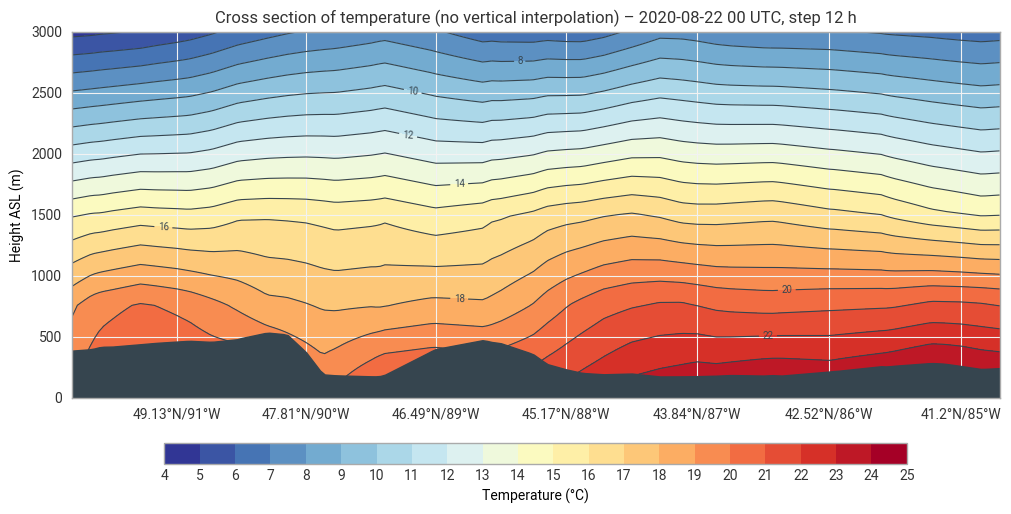

In [10]:
levels_t = list(range(4, 26))

# 7 ticks where the line crosses the longitudes 91W ... 85W (lons increase along the line)
tick_lons = np.arange(-91, -84)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

chart = ekp.Subplot(figsize=(10, 5))
# coordinates of the curvilinear grid, with the same shape as the data: (level, point)
x_grid = xs["distance"].broadcast_like(xs["t"]).values
y_grid = xs["height"].values

chart.contourf(
    xs["t"].values,
    x=x_grid,
    y=y_grid,
    style=ekp.styles.Style(levels=levels_t, colors="RdYlBu_r", ticks=levels_t),
    resample=False,
)
chart.contour(
    xs["t"].values,
    x=x_grid,
    y=y_grid,
    style=ekp.styles.Contour(
        levels=levels_t,
        colors="#36454f",
        linewidths=0.8,
        labels=True,
        label_kwargs={"label_frequency": 2, "label_fmt": "%g"},
        legend_style=None,  # no second colour bar for the lines
    ),
    resample=False,
)
chart.figure.legend(label="Temperature (°C)")
# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs["orography"], 0, x=xs["distance"], color="#36454f", alpha=1)

ax = chart.ax
ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 3000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.set_ylabel("Height ASL (m)")
ax.set_title("Cross section of temperature (no vertical interpolation) – 2020-08-22 00 UTC, step 12 h")

chart.show()